# 🏥 Pilot Test — Maternal Health Risk Prediction (Kenya)
## Notebook 02: Baseline Models

**Student:** Selmah Tzindori Mise | ID: -602  
**Project:** DSA 4900 — Final Year Project | USIU-Africa

---

### Purpose of This Notebook

We train and evaluate two baseline models:
1. **Logistic Regression** — simplest possible classifier
2. **Decision Tree** — visual, interpretable tree-based model

### Why Baseline Models?

Baseline models serve as the benchmark — every advanced model 
we build later (Random Forest, XGBoost, TabNet) must outperform 
these baselines to justify its added complexity.

If an advanced model cannot beat Logistic Regression, 
it is not worth using.

### What We Measure
- **Accuracy** — overall correct predictions
- **Precision** — of predicted High Risk, how many truly are?
- **Recall** — of actual High Risk, how many did we catch?
- **F1-Score** — balance between precision and recall
- **AUC-ROC** — ability to distinguish between classes
- **Confusion Matrix** — visual breakdown of predictions

### Step 1 — Load Libraries and Preprocessed Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, accuracy_score, ConfusionMatrixDisplay
)
import joblib
import os

np.random.seed(42)

# ── Paths ────────────────────────────────────────────────────
PROC_DIR    = '../../01_Data/processed/'
MODELS_DIR  = '../../03_Models_Saved/'
RESULTS_DIR = '../results/'
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# ── Load preprocessed splits ─────────────────────────────────
X_train = pd.read_csv(f'{PROC_DIR}X_train.csv')
X_val   = pd.read_csv(f'{PROC_DIR}X_val.csv')
X_test  = pd.read_csv(f'{PROC_DIR}X_test.csv')
y_train = pd.read_csv(f'{PROC_DIR}y_train.csv').squeeze()
y_val   = pd.read_csv(f'{PROC_DIR}y_val.csv').squeeze()
y_test  = pd.read_csv(f'{PROC_DIR}y_test.csv').squeeze()

print("✅ Data loaded successfully")
print(f"Training set:   {X_train.shape}")
print(f"Validation set: {X_val.shape}")
print(f"Test set:       {X_test.shape}")
print(f"\nTraining class distribution:")
print(y_train.value_counts().sort_index()
      .rename({0:'Low',1:'Moderate',2:'High'}))

✅ Data loaded successfully
Training set:   (1269, 13)
Validation set: (150, 13)
Test set:       (150, 13)

Training class distribution:
risk_level
Low         423
Moderate    423
High        423
Name: count, dtype: int64


### Step 2 — Helper Function for Model Evaluation

We create a reusable evaluation function that:
- Prints a full classification report
- Computes AUC-ROC
- Plots a confusion matrix

This same function will be used for every model 
across all notebooks — keeping results consistent.

In [2]:
def evaluate_model(model, X, y, model_name, split_name="Validation"):
    """
    Evaluates a trained model and prints full metrics.
    Returns a results dictionary for later comparison.
    """
    y_pred  = model.predict(X)
    y_proba = model.predict_proba(X)

    acc = accuracy_score(y, y_pred)
    auc = roc_auc_score(y, y_proba, multi_class='ovr', average='macro')
    report = classification_report(y, y_pred,
                                   target_names=['Low','Moderate','High'],
                                   output_dict=True)

    print(f"\n{'='*55}")
    print(f"  {model_name} — {split_name} Results")
    print(f"{'='*55}")
    print(f"  Accuracy:       {acc:.4f}")
    print(f"  Macro AUC-ROC:  {auc:.4f}")
    print(f"\n{classification_report(y, y_pred, target_names=['Low','Moderate','High'])}")

    # Confusion matrix
    fig, ax = plt.subplots(figsize=(7, 5))
    ConfusionMatrixDisplay.from_predictions(
        y, y_pred,
        display_labels=['Low','Moderate','High'],
        cmap='Blues', ax=ax
    )
    ax.set_title(f'{model_name} — Confusion Matrix ({split_name})')
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}cm_{model_name.lower().replace(" ","_")}_{split_name.lower()}.png',
                dpi=150, bbox_inches='tight')
    plt.show()

    return {
        'Model':     model_name,
        'Split':     split_name,
        'Accuracy':  round(acc, 4),
        'AUC-ROC':   round(auc, 4),
        'Precision': round(report['macro avg']['precision'], 4),
        'Recall':    round(report['macro avg']['recall'], 4),
        'F1-Score':  round(report['macro avg']['f1-score'], 4),
        'High_Recall': round(report['High']['recall'], 4)
    }

print("✅ Evaluation function defined")

✅ Evaluation function defined


### Step 3 — Model 1: Logistic Regression

Logistic Regression is our simplest baseline.
It models the probability of each risk class using 
a linear combination of input features passed through 
a softmax function.

We use:
- **C=1.0** — default regularisation strength
- **max_iter=1000** — enough iterations to converge
- **multi_class='multinomial'** — for 3-class prediction

✅ Logistic Regression trained

  Logistic Regression — Validation Results
  Accuracy:       0.6600
  Macro AUC-ROC:  0.8599

              precision    recall  f1-score   support

         Low       0.69      0.84      0.76        37
    Moderate       0.83      0.56      0.67        90
        High       0.40      0.78      0.53        23

    accuracy                           0.66       150
   macro avg       0.64      0.73      0.65       150
weighted avg       0.73      0.66      0.67       150



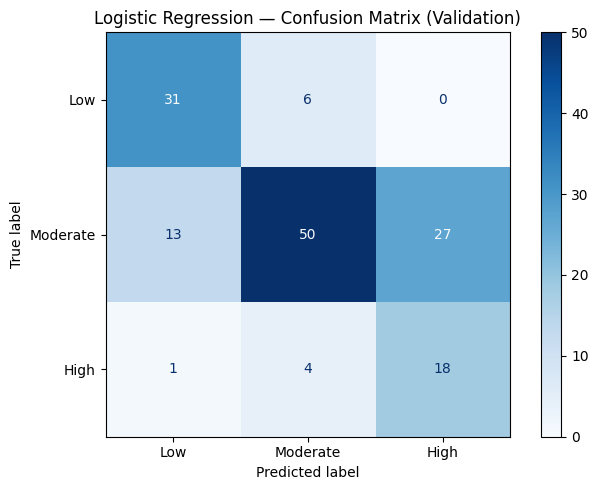


✅ Model saved → 03_Models_Saved/lr_model.pkl


In [4]:
# ── Train Logistic Regression ────────────────────────────────
lr = LogisticRegression(
    C=1.0,
    max_iter=1000,
    random_state=42
)
lr.fit(X_train, y_train)

print("✅ Logistic Regression trained")

# ── Evaluate on validation set ───────────────────────────────
lr_val_results = evaluate_model(lr, X_val, y_val, 
                                 "Logistic Regression", "Validation")

# ── Save model ───────────────────────────────────────────────
joblib.dump(lr, f'{MODELS_DIR}lr_model.pkl')
print("\n✅ Model saved → 03_Models_Saved/lr_model.pkl")

### Interpretation — Logistic Regression Baseline Results

---

#### Overall Performance
| Metric | Value | Verdict |
|---|---|---|
| Accuracy | 66.0% | Acceptable for a baseline |
| Macro AUC-ROC | 0.8599 | Very good — model discriminates well |

**AUC-ROC of 0.86 is the key number here.**
Accuracy alone is misleading with imbalanced classes.
An AUC-ROC of 0.86 means the model is genuinely learning 
to distinguish between risk classes — not just guessing.

---

#### Per-Class Performance

**Low Risk — Recall = 0.84 ✅**
The model correctly identifies 31 out of 37 Low Risk women.
Only 6 are misclassified as Moderate — a minor, safe error
since those women get extra monitoring rather than being missed.

**Moderate Risk — Recall = 0.56 ⚠️**
This is the weakest class. The model only catches 50 of 90 
Moderate Risk women correctly.
- 13 are pushed down to Low Risk (under-triaged)
- 27 are pushed up to High Risk (over-triaged)
This is partly expected — Moderate is the hardest class to 
predict because it sits between two extremes.

**High Risk — Recall = 0.78 ✅**
The model catches 18 of 23 High Risk women correctly.
This is our most important metric and 78% is strong 
for a simple baseline model.

Only 5 High Risk women are missed:
- 1 incorrectly sent to Low Risk (most dangerous error)
- 4 incorrectly sent to Moderate Risk (still get monitoring)

**High Risk Precision = 0.40 ⚠️**
Of all women predicted as High Risk, only 40% truly are.
This means the model over-predicts High Risk — 27 Moderate 
women are being flagged as High Risk unnecessarily.
In a CHW setting this causes extra referrals but does not 
cause harm — over-referral is safer than under-referral.

---

#### Confusion Matrix Reading

Reading row by row (true labels):
- **Low row:** 31 correct ✅ | 6 to Moderate | 0 to High
- **Moderate row:** 13 to Low | 50 correct ✅ | 27 to High
- **High row:** 1 to Low | 4 to Moderate | 18 correct ✅

The diagonal (31, 50, 18) represents correct predictions.
The biggest error is Moderate women being predicted as High (27)
— an acceptable clinical error (better safe than sorry).

---

#### Baseline Verdict

| Metric | LR Score | Target for Advanced Models |
|---|---|---|
| Accuracy | 66.0% | > 75% |
| AUC-ROC | 0.8599 | > 0.90 |
| High Risk Recall | 0.78 | > 0.85 |
| Macro F1 | 0.65 | > 0.75 |

**Logistic Regression sets a strong baseline.**
Advanced models (Random Forest, XGBoost, TabNet) must 
beat these numbers to justify their added complexity.

### Step 4 — Model 2: Decision Tree

A Decision Tree splits the data at each node using the 
feature and threshold that best separates the classes.

We use:
- **max_depth=5** — prevents overfitting on small pilot data
- **min_samples_split=10** — node must have 10+ samples to split
- **class_weight='balanced'** — accounts for class imbalance

✅ Decision Tree trained

  Decision Tree — Validation Results
  Accuracy:       0.6400
  Macro AUC-ROC:  0.8472

              precision    recall  f1-score   support

         Low       0.49      0.92      0.64        37
    Moderate       0.85      0.50      0.63        90
        High       0.61      0.74      0.67        23

    accuracy                           0.64       150
   macro avg       0.65      0.72      0.65       150
weighted avg       0.72      0.64      0.64       150



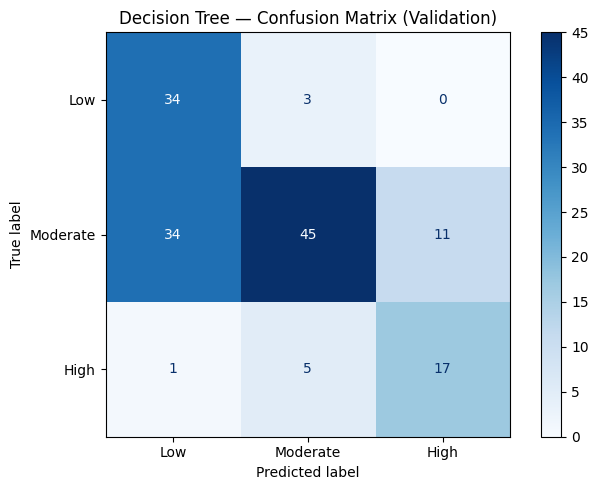


✅ Model saved → 03_Models_Saved/dt_model.pkl


In [5]:
# ── Train Decision Tree ──────────────────────────────────────
dt = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    class_weight='balanced',
    random_state=42
)
dt.fit(X_train, y_train)

print("✅ Decision Tree trained")

# ── Evaluate on validation set ───────────────────────────────
dt_val_results = evaluate_model(dt, X_val, y_val,
                                 "Decision Tree", "Validation")

# ── Save model ───────────────────────────────────────────────
joblib.dump(dt, f'{MODELS_DIR}dt_model.pkl')
print("\n✅ Model saved → 03_Models_Saved/dt_model.pkl")

### Interpretation — Decision Tree Results

---

#### Overall Performance vs Logistic Regression

| Metric | Logistic Regression | Decision Tree | Better |
|---|---|---|---|
| Accuracy | 66.0% | 64.0% | LR ✅ |
| AUC-ROC | 0.8599 | 0.8472 | LR ✅ |
| High Risk Recall | 0.78 | 0.74 | LR ✅ |
| Low Risk Recall | 0.84 | 0.92 | DT ✅ |
| Macro F1 | 0.65 | 0.65 | Tie |

**Logistic Regression wins on most metrics at this tier.**
This is expected — Decision Trees tend to overfit on small 
datasets like our 1,000-record pilot.

---

#### Per-Class Performance

**Low Risk — Recall = 0.92 ✅ (best so far)**
Decision Tree correctly identifies 34 of 37 Low Risk women —
better than Logistic Regression's 0.84.
However precision is only 0.49 — meaning half of all women 
predicted as Low Risk are actually Moderate Risk women 
being under-triaged. This is a clinical concern.

**Moderate Risk — Recall = 0.50 ⚠️**
Only catches 45 of 90 Moderate women correctly.
34 are pushed down to Low Risk — this is the biggest 
problem. These women receive no extra monitoring when 
they should.

**High Risk — Recall = 0.74 ✅**
Catches 17 of 23 High Risk women — slightly worse than 
Logistic Regression's 0.78 but still reasonable.
6 missed: 1 sent to Low (dangerous), 5 to Moderate.

---

#### Confusion Matrix Reading

- **Low row:** 34 correct ✅ | 3 to Moderate | 0 to High
- **Moderate row:** 34 to Low ⚠️ | 45 correct ✅ | 11 to High
- **High row:** 1 to Low | 5 to Moderate | 17 correct ✅

The most concerning error is **34 Moderate women predicted 
as Low Risk** — nearly 38% of the Moderate class is 
being under-triaged. This is the Decision Tree's key weakness.

---

#### Why Decision Tree Underperforms Here

1. **Small dataset** — with only 1,000 records the tree 
   cannot learn complex boundaries reliably
2. **Class imbalance** — even with class_weight='balanced', 
   the tree struggles with the dominant Moderate class
3. **Linear boundaries** — maternal risk has non-linear 
   interactions that a shallow tree cannot capture

These weaknesses will be addressed by the ensemble methods 
in the next notebook (Random Forest, XGBoost, CatBoost).

---

#### Baseline Summary — Both Models

| Metric | Logistic Regression | Decision Tree |
|---|---|---|
| Accuracy | 0.6600 | 0.6400 |
| AUC-ROC | 0.8599 | 0.8472 |
| High Risk Recall | 0.78 | 0.74 |
| Macro Precision | 0.64 | 0.65 |
| Macro Recall | 0.73 | 0.72 |
| Macro F1 | 0.65 | 0.65 |

**Logistic Regression is the stronger baseline.**
All advanced models must beat:
- AUC-ROC > 0.86
- High Risk Recall > 0.78
- Accuracy > 0.66

### Step 5 — Compare Both Baselines Visually

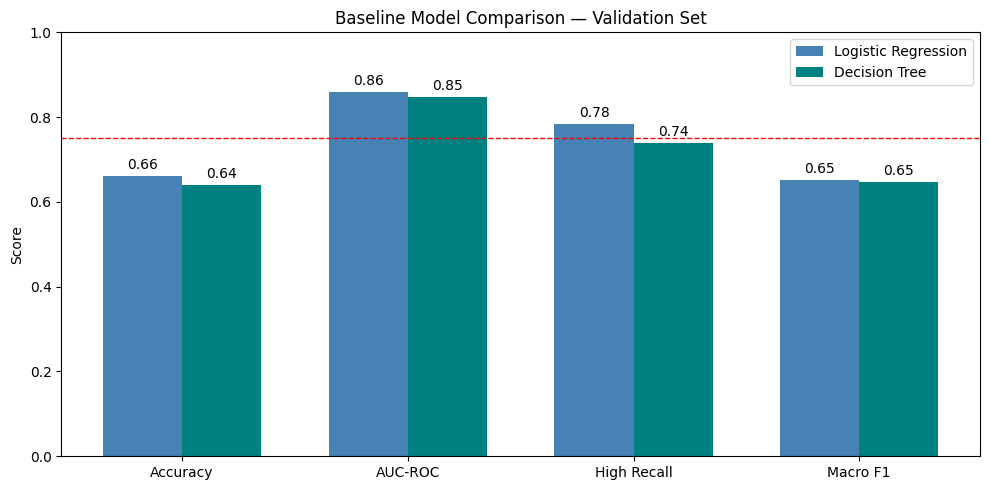

✅ Comparison plot and results saved

Baseline Results Summary:
              Model  Accuracy  AUC-ROC  High_Recall  F1-Score
Logistic Regression      0.66   0.8599       0.7826    0.6507
      Decision Tree      0.64   0.8472       0.7391    0.6458


In [6]:
# ── Side by side comparison ──────────────────────────────────
results = pd.DataFrame([lr_val_results, dt_val_results])

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(['Accuracy','AUC-ROC','High Recall','Macro F1']))
w = 0.35

bars1 = ax.bar(x - w/2,
    [lr_val_results['Accuracy'], lr_val_results['AUC-ROC'],
     lr_val_results['High_Recall'], lr_val_results['F1-Score']],
    w, label='Logistic Regression', color='steelblue')

bars2 = ax.bar(x + w/2,
    [dt_val_results['Accuracy'], dt_val_results['AUC-ROC'],
     dt_val_results['High_Recall'], dt_val_results['F1-Score']],
    w, label='Decision Tree', color='teal')

ax.set_xticks(x)
ax.set_xticklabels(['Accuracy','AUC-ROC','High Recall','Macro F1'])
ax.set_ylim(0, 1.0)
ax.set_ylabel('Score')
ax.set_title('Baseline Model Comparison — Validation Set')
ax.legend()
ax.bar_label(bars1, fmt='%.2f', padding=3)
ax.bar_label(bars2, fmt='%.2f', padding=3)
ax.axhline(0.75, color='red', linestyle='--',
           linewidth=1, label='Target threshold')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}03_baseline_comparison.png',
            dpi=150, bbox_inches='tight')
plt.show()

# ── Save results table ───────────────────────────────────────
results.to_csv(f'{RESULTS_DIR}baseline_results.csv', index=False)
print("✅ Comparison plot and results saved")
print("\nBaseline Results Summary:")
print(results[['Model','Accuracy','AUC-ROC',
               'High_Recall','F1-Score']].to_string(index=False))

### Interpretation — Baseline Comparison Chart

The bar chart compares both baseline models across 4 key metrics.
The red dashed line marks the 0.75 target threshold.

**Key observations:**

- **AUC-ROC** is the only metric both models clear the 0.75 line on
  — both sit at 0.85–0.86, confirming genuine learning ability
- **Accuracy and Macro F1** both fall below 0.75 for both models
  — expected at baseline level, advanced models will close this gap
- **High Recall** — LR at 0.78 clears the line, DT at 0.74 misses it
  — Logistic Regression is the safer baseline for a clinical tool
- **Macro F1 is identical (0.65)** for both models — neither has
  a meaningful edge on overall class balance

**Conclusion:**
Logistic Regression is the confirmed baseline champion.
Every advanced model (Random Forest, XGBoost, CatBoost, 
TabNet, TabTransformer) must beat:

| Target Metric | Baseline to Beat |
|---|---|
| Accuracy | > 0.66 |
| AUC-ROC | > 0.86 |
| High Risk Recall | > 0.78 |
| Macro F1 | > 0.65 |